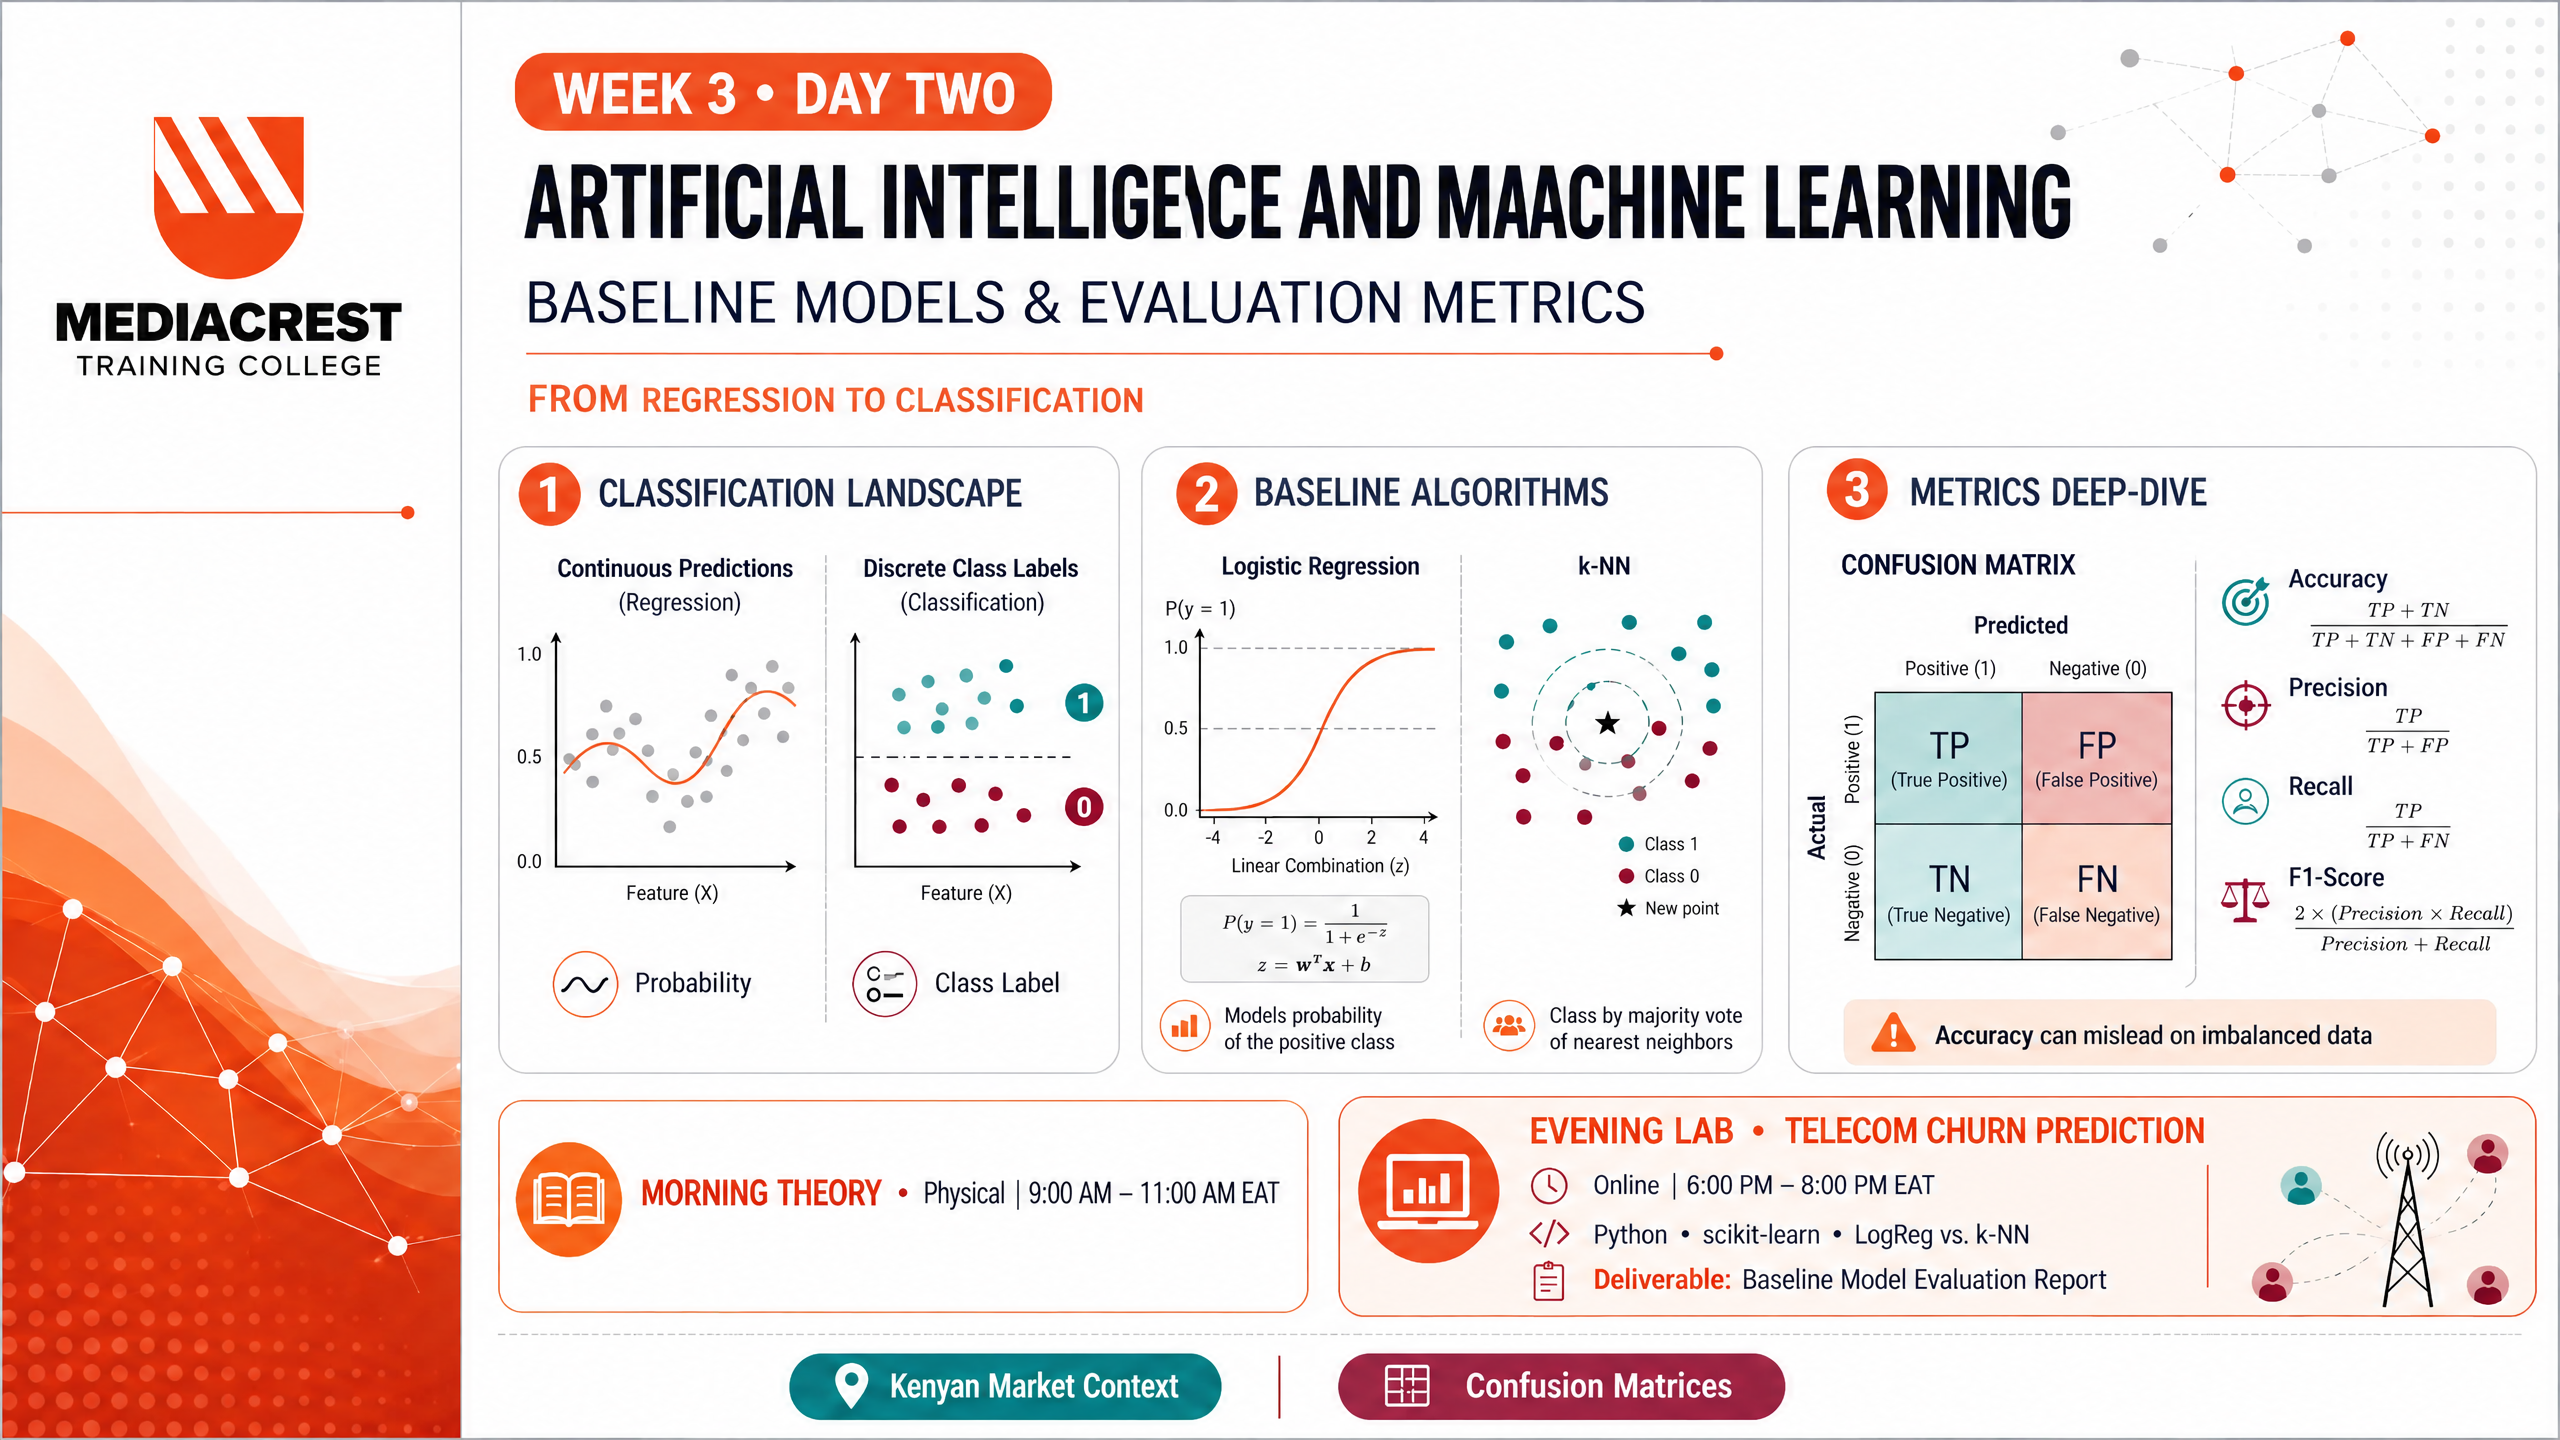

## **MACHINE LEARNING**
### **CLASSIFICATION AND BASELINE MODEL DEVELOPMENT (HYPERTENSION PREDICTION)**

### **1. STAGE 1: PROBLEM FORMULATION AND HYPOTHESIS STATING**
**Clinical Objective**: Predicting the presence of hypertension (HTN) in HIV cohort-based patients. 

The data include
- Demographic Information 
- Clinical markers
- HIV related variables

**Target Variable**: Hypertension (1 = Hypertensive, 0 = Non-Hypertensive)

**Hypotheses**: 

**`Null hypothesis`:** There is no statistically significant difference between tree-based models and linear or other non-linear models in the prediction of hypertension. 

**`Alternative hypothesis`:** Tree-Based Model (Decision Tree, Random Forest, XGboost) will likely outperform linear and other non-linear models in the prediction of hypertension.

### **2. STAGE 2: LIBRARY IMPORTATION, DATA LOADING AND EXPLORATORY DATA ANALYSIS**

#### **2.1. Load all the Required Libraries**

> **`Preliminary Libraries`**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

> **`Modeling and ML Libraries`**

In [3]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

> **`Algorithm Libraries`**

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

> **`Metrics and Evaluation Libraries`**

In [51]:
from sklearn.metrics import (accuracy_score, 
                             precision_score, 
                             recall_score, 
                             f1_score, 
                             roc_auc_score,
                             confusion_matrix,
                             classification_report,
                             precision_recall_curve,
                             roc_curve,
                             average_precision_score,
                             auc)

> **`Fix the Modeling Reproducibility`**

In [6]:
SEED = 42
np.random.seed(SEED)

> **`Filter all the Warning Accompanying the Outputs`**

In [7]:
warnings.filterwarnings('ignore')

#### **2.2. Loading the Data**

In [8]:
df = pd.read_csv('htn_dat.csv', na_values=['?', 'NA', 'NaN', 'nan', 'na', 'N/A', 'n/a', ''])

##### **2.2.1. Check the General Data Information**

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  4999 non-null   int64  
 1   DBP                 4999 non-null   int64  
 2   SBP                 4999 non-null   int64  
 3   BMI                 4329 non-null   float64
 4   age                 4999 non-null   float64
 5   married             4835 non-null   float64
 6   male.gender         4999 non-null   int64  
 7   hgb_centered        3605 non-null   float64
 8   adv_HIV             3038 non-null   float64
 9   survtime            4999 non-null   int64  
 10  event               4999 non-null   int64  
 11  arv_naive           4999 non-null   int64  
 12  urban.clinic        4999 non-null   int64  
 13  log_creat_centered  3461 non-null   float64
 14  IPW_weight          4999 non-null   float64
 15  SBP_ge120           4999 non-null   int64  
dtypes: flo

##### **2.2.2. Check the Presence of Missing Values**

In [10]:
df.isnull().sum()

ID                       0
DBP                      0
SBP                      0
BMI                    670
age                      0
married                164
male.gender              0
hgb_centered          1394
adv_HIV               1961
survtime                 0
event                    0
arv_naive                0
urban.clinic             0
log_creat_centered    1538
IPW_weight               0
SBP_ge120                0
dtype: int64

##### **2.2.3. Check the Percentage of Missing Values**

In [11]:
df.isnull().sum()*100/len(df)

ID                     0.000000
DBP                    0.000000
SBP                    0.000000
BMI                   13.402681
age                    0.000000
married                3.280656
male.gender            0.000000
hgb_centered          27.885577
adv_HIV               39.227846
survtime               0.000000
event                  0.000000
arv_naive              0.000000
urban.clinic           0.000000
log_creat_centered    30.766153
IPW_weight             0.000000
SBP_ge120              0.000000
dtype: float64

##### **2.2.4. Feature Engineering- Create the Target Variable**

In [12]:
df['HTN'] = ((df['SBP'] >= 140) | (df['DBP'] >= 90)).astype(int)

In [13]:
df.head()

,ID,DBP,SBP,BMI,age,married,male.gender,hgb_centered,adv_HIV,survtime,event,arv_naive,urban.clinic,log_creat_centered,IPW_weight,SBP_ge120,HTN
0,16097,60,90,NaN,28.000000,0.0,0,NaN,NaN,338,1,1,0,NaN,0.924379,0,0
1,930,75,110,27.339912,26.458590,1.0,0,-3.9,0.0,439,1,1,1,5.421770e-02,1.163862,0,0
2,6877,60,80,17.689789,42.951405,0.0,0,-3.2,NaN,752,1,1,0,-3.597409e-01,0.721148,0,0
3,36464,60,90,19.854080,50.149212,1.0,1,NaN,NaN,526,1,1,1,NaN,0.829452,0,0
4,36180,60,100,21.295294,30.554415,0.0,1,-0.4,NaN,215,1,1,0,-1.000000e-07,0.856046,0,0


##### **2.2.5. Drop `ID`, `DBP`, `SBP`, `survtime`, `event`, `IPW_weight`**

In [14]:
cols_to_drop = ['ID','SBP', 'DBP', 'survtime', 'event', 'IPW_weight']

In [15]:
df = df.drop(columns=cols_to_drop)

> **`Alternatively Way to Drop Unwanted Columns`**

In [16]:
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

In [17]:
df.head(10)

,BMI,age,married,male.gender,hgb_centered,adv_HIV,arv_naive,urban.clinic,log_creat_centered,SBP_ge120,HTN
0,NaN,28.000000,0.0,0,NaN,NaN,1,0,NaN,0,0
1,27.339912,26.458590,1.0,0,-3.9,0.0,1,1,5.421770e-02,0,0
2,17.689789,42.951405,0.0,0,-3.2,NaN,1,0,-3.597409e-01,0,0
3,19.854080,50.149212,1.0,1,NaN,NaN,1,1,NaN,0,0
4,21.295294,30.554415,0.0,1,-0.4,NaN,1,0,-1.000000e-07,0,0
5,16.880194,20.372347,1.0,0,-4.0,NaN,1,0,3.344296e-01,0,0
6,22.038567,28.793976,0.0,0,NaN,NaN,1,1,NaN,0,0
7,21.580042,49.152634,0.0,1,0.8,NaN,0,0,-2.231437e-01,0,0
8,19.067711,29.705681,1.0,0,-1.0,NaN,1,0,-1.337490e-02,0,0
9,26.058353,28.208077,1.0,0,NaN,NaN,1,0,NaN,0,0


> **`Specify the Valid Columns for the Next Stages of Modeling`**

In [18]:
valid_cols = ['BMI', 'age', 'married', 
              'male.gender', 'hgb_centered', 
              'adv_HIV', 'arv_naive', 'urban.clinic', 'log_creat_centered', 'HTN']

df = df[valid_cols]

In [19]:
df.head(12)

,BMI,age,married,male.gender,hgb_centered,adv_HIV,arv_naive,urban.clinic,log_creat_centered,HTN
0,NaN,28.000000,0.0,0,NaN,NaN,1,0,NaN,0
1,27.339912,26.458590,1.0,0,-3.90,0.0,1,1,5.421770e-02,0
2,17.689789,42.951405,0.0,0,-3.20,NaN,1,0,-3.597409e-01,0
3,19.854080,50.149212,1.0,1,NaN,NaN,1,1,NaN,0
4,21.295294,30.554415,0.0,1,-0.40,NaN,1,0,-1.000000e-07,0
5,16.880194,20.372347,1.0,0,-4.00,NaN,1,0,3.344296e-01,0
6,22.038567,28.793976,0.0,0,NaN,NaN,1,1,NaN,0
7,21.580042,49.152634,0.0,1,0.80,NaN,0,0,-2.231437e-01,0
8,19.067711,29.705681,1.0,0,-1.00,NaN,1,0,-1.337490e-02,0
9,26.058353,28.208077,1.0,0,NaN,NaN,1,0,NaN,0


> **`Alterntive Approach to Select the Needed Columns`**

In [20]:
df = df[[col for col in valid_cols if col in df.columns]]
df.head(12)

,BMI,age,married,male.gender,hgb_centered,adv_HIV,arv_naive,urban.clinic,log_creat_centered,HTN
0,NaN,28.000000,0.0,0,NaN,NaN,1,0,NaN,0
1,27.339912,26.458590,1.0,0,-3.90,0.0,1,1,5.421770e-02,0
2,17.689789,42.951405,0.0,0,-3.20,NaN,1,0,-3.597409e-01,0
3,19.854080,50.149212,1.0,1,NaN,NaN,1,1,NaN,0
4,21.295294,30.554415,0.0,1,-0.40,NaN,1,0,-1.000000e-07,0
5,16.880194,20.372347,1.0,0,-4.00,NaN,1,0,3.344296e-01,0
6,22.038567,28.793976,0.0,0,NaN,NaN,1,1,NaN,0
7,21.580042,49.152634,0.0,1,0.80,NaN,0,0,-2.231437e-01,0
8,19.067711,29.705681,1.0,0,-1.00,NaN,1,0,-1.337490e-02,0
9,26.058353,28.208077,1.0,0,NaN,NaN,1,0,NaN,0


### **2.3. Data Exploration**

##### **2.3.1. Variable Name, Definition and Measurement**

| Variable | Definition | Type | Clinical Relevance |
|---|---|---|---|
| **age** | Patient's age in years | Continuous | Strong predictor of cardiovascular risk and arterial stiffness. |
| **male.gender** | Biological sex | Binary | Men often have different HTN prevalence and risk profiles. |
| **married** | Marital status | Binary | Socioeconomic/demographic proxy. |
| **BMI** | Body Mass Index | Continuous | Obesity is a primary modifiable risk factor for HTN. |
| **hgb_centered** | Centered Hemoglobin | Continuous | Anemia/polycythemia can relate to cardiovascular/renal health. |
| **adv_HIV** | Advanced HIV disease | Binary | Advanced immunosuppression may affect vascular health. |
| **arv_naive** | Antiretroviral naive | Binary | ART exposure can influence metabolic and cardiovascular risk. |
| **urban.clinic** | Clinic location (Urban) | Binary | Urban vs rural lifestyle and dietary differences. |
| **log_creat_centered**| Centered Log Creatinine | Continuous | Marker of kidney function; closely tied to HTN and renal disease. |
| **HTN (Target)** | Hypertension status | Binary | Derived as 1 if SBP ≥ 140 or DBP ≥ 90, else 0. |


##### **2.3.2. Distribution of the Target Variable**

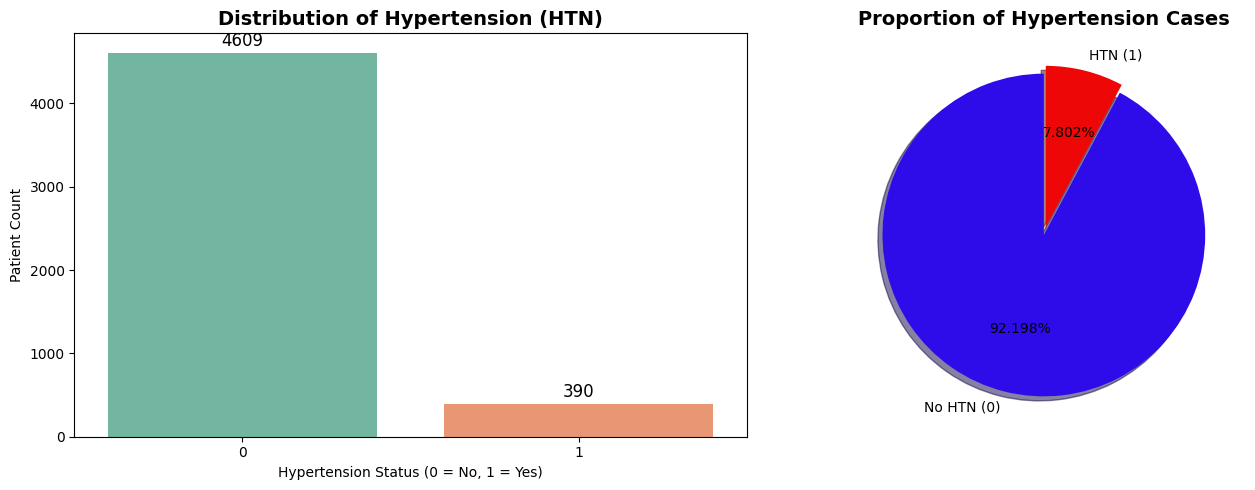

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Countplot
sns.countplot(x='HTN', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Distribution of Hypertension (HTN)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hypertension Status (0 = No, 1 = Yes)')
axes[0].set_ylabel('Patient Count')

# Add count labels on top of bars
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='baseline', fontsize=12, color='black', xytext=(0, 5),
                     textcoords='offset points')

# B. Pie Chart
htn_counts = df['HTN'].value_counts()
axes[1].pie(htn_counts, labels=['No HTN (0)', 
                                'HTN (1)'], autopct='%1.3f%%',
            colors=["#2e0cea", "#ee0707",], startangle=90, 
            explode=(0, 0.05), shadow=True)
axes[1].set_title('Proportion of Hypertension Cases', 
                  fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### **2.4. Extraction of the Target Variable and Features**

In [22]:
X = df.drop(columns=['HTN'])
y = df['HTN']

#### **2.5. Categorize the Features**

In [29]:
num_features = ['age', 'BMI', 'hgb_centered', 'log_creat_centered']
cat_features = ['married', 'male.gender', 'adv_HIV', 'arv_naive', 'urban.clinic']
ordinal_features = []  # Add any ordinal features if present

#### **2.6. Select the Data to Mirror the Categorized Variables**

In [30]:
num_features = [f for f in num_features if f in X.columns]
cat_features = [f for f in cat_features if f in X.columns]

### **3: STAGE 3: DATA PREPROCESSING AND ML PIPELINE CLEATION**

#### **3.1. Create the Numeric and Categorical Pipelines**

In [43]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

#### **3.2. Create the Column Transformer**

In [44]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_transformer, num_features),
        ('categorical', categorical_transformer, cat_features)
        #('ordinal', ordinal_transformer, ordinal_features)
    ])

### **4. STAGE 4: DATA PARTITIONING AND MODEL TRAINING**

#### **4.1. Partition the data set**

In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, 
                                                    random_state=SEED, 
                                                    stratify=y)

print((f"Training Set: {X_train.shape[0]}| Class Distribution: {y_train.value_counts().to_dict()}"))
print((f"Testing Set: {X_test.shape[0]}| Class Distribution: {y_test.value_counts().to_dict()}"))

Training Set: 3999| Class Distribution: {0: 3687, 1: 312}
Testing Set: 1000| Class Distribution: {0: 922, 1: 78}


> **``Check the Class Proportion for Positive and Negative Instances in the Testing and Training set``**

In [46]:
## Check the Class Proportion for Positive and Negative Instances in the Testing and Training set
print("Training Set Class Proportions:")
print(y_train.value_counts(normalize=True))
print("Testing Set Class Proportions:")
print(y_test.value_counts(normalize=True))

Training Set Class Proportions:
HTN
0    0.92198
1    0.07802
Name: proportion, dtype: float64
Testing Set Class Proportions:
HTN
0    0.922
1    0.078
Name: proportion, dtype: float64


#### **4.2. Create the Modeling Pipeline**

In [47]:
pos_weight_train = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Positive Class Weight for Training Set: {pos_weight_train}")

lr_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('lr', LogisticRegression(class_weight='balanced', 
                                                        random_state=SEED, 
                                                        max_iter=1000))
                              ])

knn_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('knn', KNeighborsClassifier())
                               ])

svm_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('svm', SVC(class_weight='balanced',
                                           random_state=SEED,
                                           probability=True))
                               ])

nb_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('nb', GaussianNB())
                              ])

Positive Class Weight for Training Set: 11.817307692307692


#### **4.3. Create the Hyperparameter Grid**

In [48]:
param_dist_lr = {
    'lr__C': [0.01, 0.1, 1, 10, 100],
    'lr__penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'lr__solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
}

param_dist_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11], 
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan', 'minkowski']
}

param_dist_svm = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'svm__gamma': ['scale', 'auto']
}

param_dist_nb = {
    'nb__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}

#### **4.4. Model Training**

In [49]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Starting the RandomizedSearchCV (n_iter = 30, 5-fold StratifiedKFold):")

results = {}
training_times = {}

all_pipelines = [
    ('Logistic Regression', lr_pipeline, param_dist_lr),
    ('K-Nearest Neighbors', knn_pipeline, param_dist_knn),
    ('Support Vector Machine', svm_pipeline, param_dist_svm),
    ('Naive Bayes', nb_pipeline, param_dist_nb)
]

for name, pipeline, params in all_pipelines:
    print(f"\n{name} - RandomizedSearchCV")
    start_time = time.time()
    
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=params,
        n_iter=30,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1,
        random_state=SEED)
    
    search.fit(X_train, y_train)
    training_time = time.time() - start_time
    results[name] = search
    print(f"{name} trained. Best ROC AUC: {search.best_score_:.4f} | Time: {training_time:.2f} seconds | Best Params: {search.best_params_}")
   

    
   

Starting the RandomizedSearchCV (n_iter = 30, 5-fold StratifiedKFold):

Logistic Regression - RandomizedSearchCV
Logistic Regression trained. Best ROC AUC: 0.6810 | Time: 3.15 seconds | Best Params: {'lr__solver': 'saga', 'lr__penalty': 'l1', 'lr__C': 0.01}

K-Nearest Neighbors - RandomizedSearchCV
K-Nearest Neighbors trained. Best ROC AUC: 0.6274 | Time: 5.16 seconds | Best Params: {'knn__weights': 'uniform', 'knn__n_neighbors': 11, 'knn__metric': 'manhattan'}

Support Vector Machine - RandomizedSearchCV
Support Vector Machine trained. Best ROC AUC: 0.6883 | Time: 423.06 seconds | Best Params: {'svm__kernel': 'poly', 'svm__gamma': 'auto', 'svm__C': 0.1}

Naive Bayes - RandomizedSearchCV
Naive Bayes trained. Best ROC AUC: 0.6423 | Time: 0.57 seconds | Best Params: {'nb__var_smoothing': 1e-05}


### **5. STAGE 5: MODEL EVALUATIONS**

#### **5.1. Hold Out (Testing Set) Cross Validation**

In [52]:
print("\n" + "="*110)
print("HOLD-OUT TEST SET EVALUATION")
print("="*110)

eval_metrics = {}
for name, search in results.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }
    
    # Precision-Recall AUC (crucial for imbalanced/clinical tasks)
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    metrics['PR-AUC'] = auc(rec, prec)
    
    eval_metrics[name] = {**metrics, 'y_pred': y_pred, 'y_prob': y_prob, 'model': model}
    
    print(f"\n📊 {name}")
    for k, v in metrics.items():
        print(f"  {k:<12}: {v:.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


HOLD-OUT TEST SET EVALUATION

📊 Logistic Regression
  Accuracy    : 0.6770
  Precision   : 0.1470
  Recall      : 0.6538
  F1-Score    : 0.2400
  ROC-AUC     : 0.7175
  PR-AUC      : 0.1650
Confusion Matrix:
[[626 296]
 [ 27  51]]

📊 K-Nearest Neighbors
  Accuracy    : 0.9210
  Precision   : 0.0000
  Recall      : 0.0000
  F1-Score    : 0.0000
  ROC-AUC     : 0.5417
  PR-AUC      : 0.0916
Confusion Matrix:
[[921   1]
 [ 78   0]]

📊 Support Vector Machine
  Accuracy    : 0.8060
  Precision   : 0.1667
  Recall      : 0.3718
  F1-Score    : 0.2302
  ROC-AUC     : 0.7076
  PR-AUC      : 0.1516
Confusion Matrix:
[[777 145]
 [ 49  29]]

📊 Naive Bayes
  Accuracy    : 0.8850
  Precision   : 0.1064
  Recall      : 0.0641
  F1-Score    : 0.0800
  ROC-AUC     : 0.6643
  PR-AUC      : 0.1201
Confusion Matrix:
[[880  42]
 [ 73   5]]


#### **Confusion Matrix Graph for Logistic Regression**

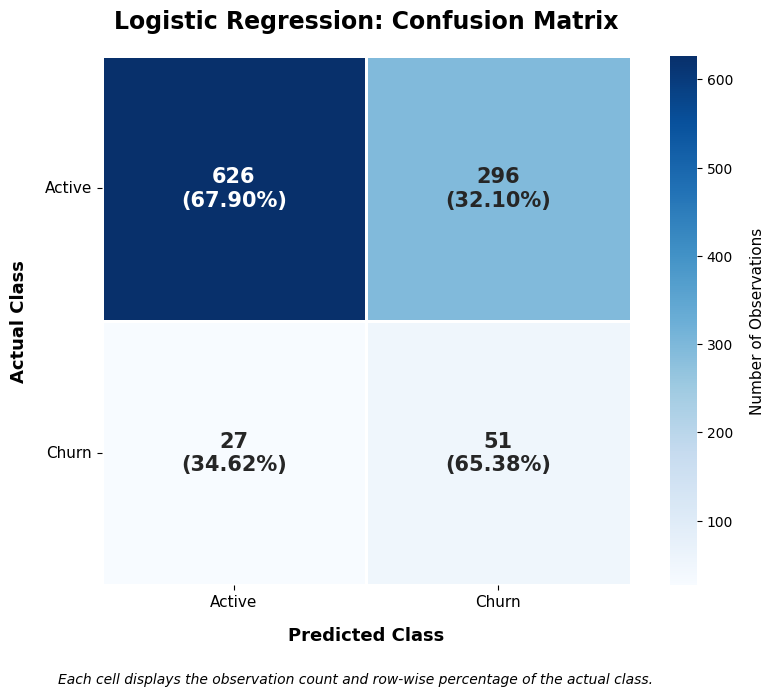

In [55]:
# Logistic Regression confusion matrix
cm = np.array([
    [626, 296],
    [27,   51]
])

# Calculate row-wise percentages
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

# Class labels
labels = ["Active", "Churn"]

# Create annotations showing counts and percentages
annotations = np.array([
    [
        f"{cm[i, j]:,}\n({cm_percent[i, j]:.2f}%)"
        for j in range(cm.shape[1])
    ]
    for i in range(cm.shape[0])
])

# Plot confusion matrix
plt.figure(figsize=(9, 7))

ax = sns.heatmap(
    cm,
    annot=annotations,
    fmt="",
    cmap="Blues",
    linewidths=2,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    annot_kws={"size": 15, "weight": "bold"},
    square=True
)

# Labels and title
plt.title(
    "Logistic Regression: Confusion Matrix",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Predicted Class", fontsize=13, fontweight="bold", labelpad=12)
plt.ylabel("Actual Class", fontsize=13, fontweight="bold", labelpad=12)

plt.xticks(fontsize=11, rotation=0)
plt.yticks(fontsize=11, rotation=0)

# Color bar label
colorbar = ax.collections[0].colorbar
colorbar.set_label("Number of Observations", fontsize=11, labelpad=12)

# Footnote explaining percentages
plt.figtext(
    0.5, 0.015,
    "Each cell displays the observation count and row-wise percentage of the actual class.",
    ha="center",
    fontsize=10,
    style="italic"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

# Save high-resolution figure
plt.savefig(
    "logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### **Present the Performance Results as a Data Frame**

In [53]:
results_df = pd.DataFrame({
    model_name: {
        'Accuracy': metrics['Accuracy'],
        'Precision': metrics['Precision'],
        'Recall': metrics['Recall'],
        'F1-Score': metrics['F1-Score'],
        'ROC-AUC': metrics['ROC-AUC'],
        'PR-AUC': metrics['PR-AUC']
    }
    for model_name, metrics in eval_metrics.items()
})

results_df = results_df.round(4)
display(results_df)

,Logistic Regression,K-Nearest Neighbors,Support Vector Machine,Naive Bayes
Accuracy,0.6770,0.9210,0.8060,0.8850
Precision,0.1470,0.0000,0.1667,0.1064
Recall,0.6538,0.0000,0.3718,0.0641
F1-Score,0.2400,0.0000,0.2302,0.0800
ROC-AUC,0.7175,0.5417,0.7076,0.6643
PR-AUC,0.1650,0.0916,0.1516,0.1201


### **NEXT SESSION 19TH OCT 2026**
#### **ENSEMBLE AND TREE-BASED MODELS**